In [1]:
# Importamos las librerías necesarias para trabajar con K-Medias
import pandas as pd
import matplotlib.pyplot as mp
import seaborn as sb
import os
from sklearn.cluster import KMeans
from sklearn import datasets

# Cargamos la base de datos Iris
dataset = pd.read_csv("iris.csv")
dataset.head()



,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [2]:
# Seleccionamos las cuatro variables originales de Iris
# No realizamos ninguna transformación de los datos

fields = dataset.iloc[:,[0,1,2,3]].values

print(fields)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [4]:
# Evitamos que se muestren advertencias durante la ejecución

import warnings
warnings.filterwarnings('ignore')

In [5]:
# Calculamos el WCSS para diferentes números de clusters
# Utilizaremos de 1 a 10 clusters

wcss = []

for index in range(1,11):
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)
    kmeans.fit(fields)

    wcss.append(kmeans.inertia_)

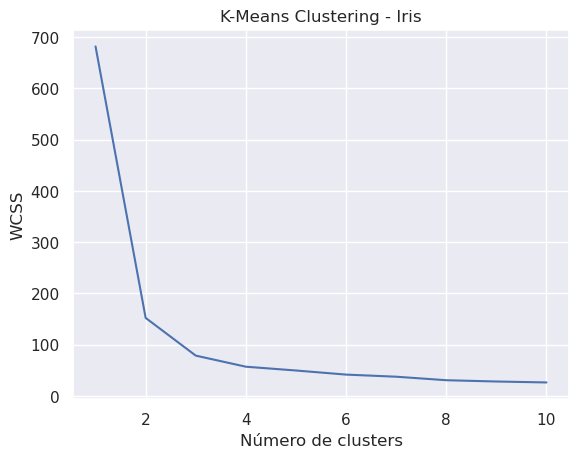

In [6]:
# Graficamos el método del codo para identificar el número de clusters

sb.set()
mp.plot(range(1,11), wcss)
mp.title("K-Means Clustering - Iris")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS")
mp.show()

In [7]:
# Importamos la función para calcular el indicador Silhouette

from sklearn.metrics import silhouette_score

In [8]:
# Calculamos el indicador Silhouette para diferentes números de clusters
# Utilizamos las cuatro variables originales de Iris

X = dataset.iloc[:, [0,1,2,3]].to_numpy()

for j in range(2, 11):
    kmeans = KMeans(n_clusters = j, random_state = 42)
    kmeans.fit_predict(X)

    # Calculamos el Score de Silueta
    score = silhouette_score(X, kmeans.labels_, metric='euclidean')

    print("Score Silhouette:", "k = ", j, ":", score)

Score Silhouette: k =  2 : 0.6810461692117465
Score Silhouette: k =  3 : 0.5511916046195927
Score Silhouette: k =  4 : 0.49764331793219296
Score Silhouette: k =  5 : 0.4930804067193529
Score Silhouette: k =  6 : 0.36784649847122536
Score Silhouette: k =  7 : 0.3542978877198859
Score Silhouette: k =  8 : 0.34467972180562056
Score Silhouette: k =  9 : 0.31558878533897866
Score Silhouette: k =  10 : 0.3014143745325154


In [9]:
# Aplicamos K-Medias con 3 clusters a los datos originales
# Obtenemos el grupo asignado a cada observación

kmeans = KMeans(n_clusters = 3, init = "k-means++", random_state = 42)

cluster_values = kmeans.fit_predict(fields)

print(cluster_values)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


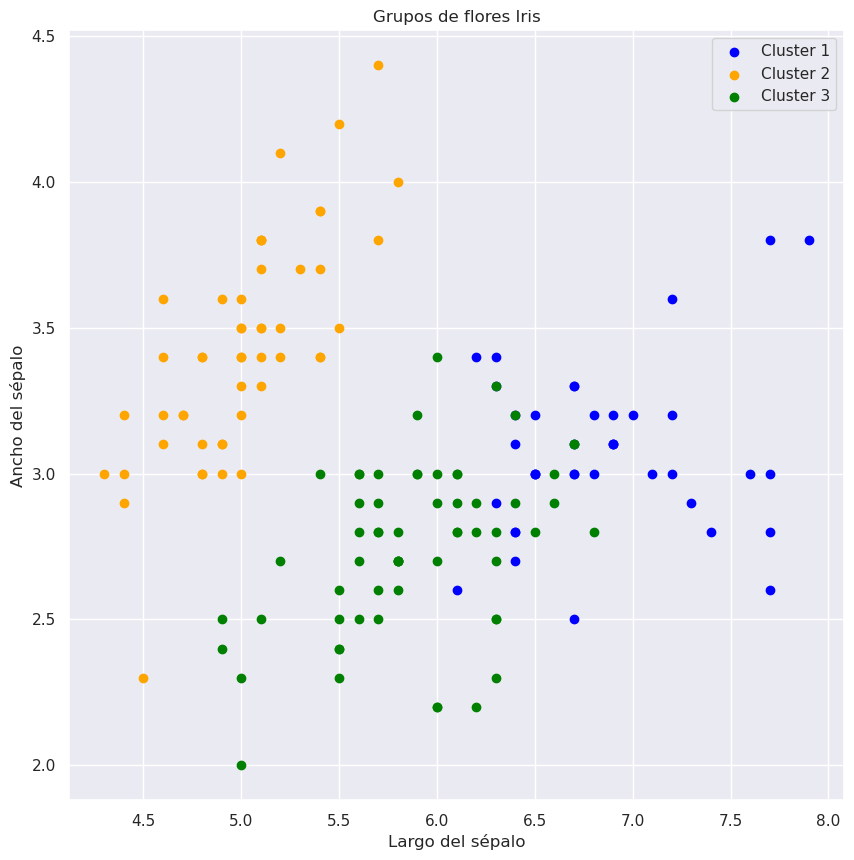

In [10]:
# Graficamos los 3 clusters encontrados con las variables originales
# Mostramos el largo y ancho del sépalo en los ejes

mp.figure(figsize = (10,10))

mp.scatter(fields[cluster_values==0,0], fields[cluster_values==0,1],
           c = 'blue', label = 'Cluster 1')

mp.scatter(fields[cluster_values==1,0], fields[cluster_values==1,1],
           c = 'orange', label = 'Cluster 2')

mp.scatter(fields[cluster_values==2,0], fields[cluster_values==2,1],
           c = 'green', label = 'Cluster 3')

mp.title('Grupos de flores Iris')
mp.xlabel("Largo del sépalo")
mp.ylabel("Ancho del sépalo")
mp.legend()
mp.show()

In [11]:
# Seleccionamos las cuatro variables de Iris
# Estas variables serán transformadas mediante PCA

fields2 = dataset.iloc[:, [0,1,2,3]].values

print(fields2)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [12]:
# Aplicamos PCA para reducir las cuatro variables a dos componentes principales

from sklearn import decomposition

pca = decomposition.PCA(n_components=2)

pca.fit(fields2)

fields2 = pca.transform(fields2)

fields2

array([[-2.68412563,  0.31939725],
       [-2.71414169, -0.17700123],
       [-2.88899057, -0.14494943],
       [-2.74534286, -0.31829898],
       [-2.72871654,  0.32675451],
       [-2.28085963,  0.74133045],
       [-2.82053775, -0.08946138],
       [-2.62614497,  0.16338496],
       [-2.88638273, -0.57831175],
       [-2.6727558 , -0.11377425],
       [-2.50694709,  0.6450689 ],
       [-2.61275523,  0.01472994],
       [-2.78610927, -0.235112  ],
       [-3.22380374, -0.51139459],
       [-2.64475039,  1.17876464],
       [-2.38603903,  1.33806233],
       [-2.62352788,  0.81067951],
       [-2.64829671,  0.31184914],
       [-2.19982032,  0.87283904],
       [-2.5879864 ,  0.51356031],
       [-2.31025622,  0.39134594],
       [-2.54370523,  0.43299606],
       [-3.21593942,  0.13346807],
       [-2.30273318,  0.09870885],
       [-2.35575405, -0.03728186],
       [-2.50666891, -0.14601688],
       [-2.46882007,  0.13095149],
       [-2.56231991,  0.36771886],
       [-2.63953472,

In [13]:
# Calculamos el WCSS utilizando los datos transformados mediante PCA

wcss2 = []

for index in range(1,11):
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)
    kmeans.fit(fields2)

    wcss2.append(kmeans.inertia_)

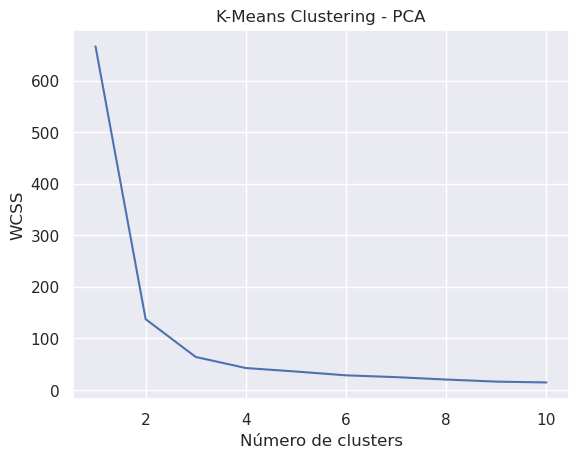

In [14]:
# Graficamos el método del codo para los datos reducidos mediante PCA

sb.set()
mp.plot(range(1,11), wcss2)
mp.title("K-Means Clustering - PCA")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS")
mp.show()

In [15]:
# Calculamos el indicador Silhouette utilizando los dos componentes de PCA

X2 = fields2

for j in range(2, 11):
    kmeans = KMeans(n_clusters = j, random_state = 42)
    kmeans.fit_predict(X2)

    # Calculamos el Score de Silueta
    score = silhouette_score(X2, kmeans.labels_, metric='euclidean')

    print("Score Silhouette:", "k = ", j, ":", score)

Score Silhouette: k =  2 : 0.7056703225102109
Score Silhouette: k =  3 : 0.5976764219547994
Score Silhouette: k =  4 : 0.5577409232246783
Score Silhouette: k =  5 : 0.5100407194899199
Score Silhouette: k =  6 : 0.40319738737442673
Score Silhouette: k =  7 : 0.3868263997713608
Score Silhouette: k =  8 : 0.44076033249654045
Score Silhouette: k =  9 : 0.4020143876366366
Score Silhouette: k =  10 : 0.41588658017532376


In [16]:
# Aplicamos K-Medias con 3 clusters a los datos reducidos mediante PCA
# Guardamos las etiquetas de los clusters obtenidos

kmeans = KMeans(n_clusters = 3, init = "k-means++", random_state = 42)

cluster_values2 = kmeans.fit_predict(fields2)

print(cluster_values2)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


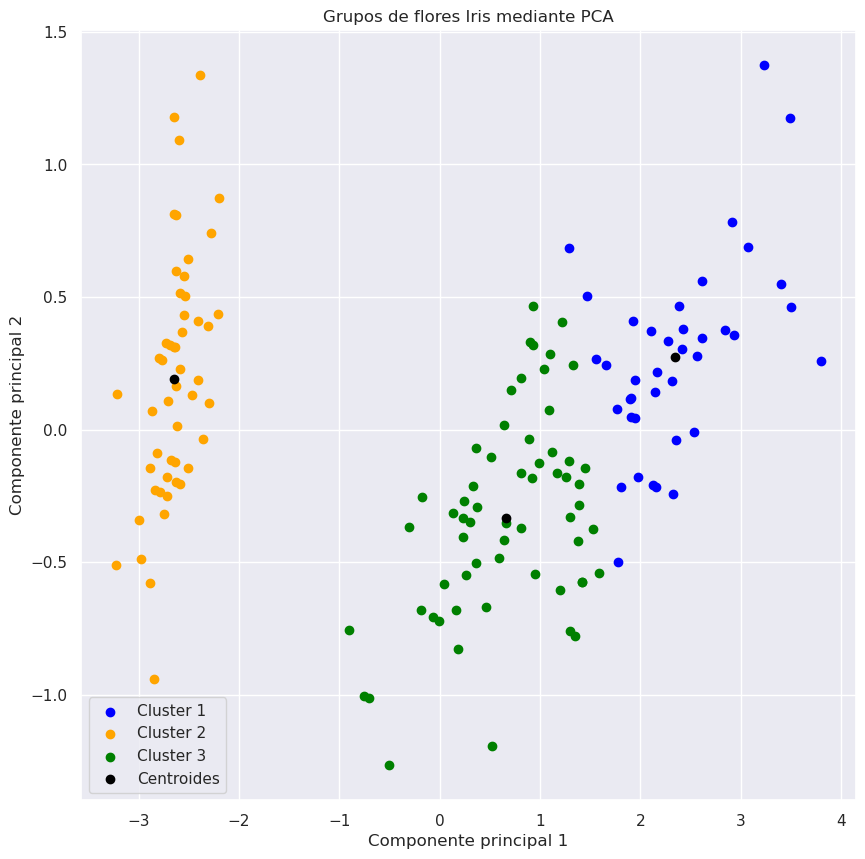

In [17]:
# Graficamos los 3 clusters obtenidos después de aplicar PCA
# Los ejes representan los dos componentes principales

mp.figure(figsize = (10,10))

mp.scatter(fields2[cluster_values2==0,0], fields2[cluster_values2==0,1],
           c = 'blue', label = 'Cluster 1')

mp.scatter(fields2[cluster_values2==1,0], fields2[cluster_values2==1,1],
           c = 'orange', label = 'Cluster 2')

mp.scatter(fields2[cluster_values2==2,0], fields2[cluster_values2==2,1],
           c = 'green', label = 'Cluster 3')

mp.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1],
           c = 'black', label = 'Centroides')

mp.title('Grupos de flores Iris mediante PCA')
mp.xlabel("Componente principal 1")
mp.ylabel("Componente principal 2")
mp.legend()
mp.show()

In [18]:
# Comparamos los agrupamientos obtenidos antes y después de PCA
# ARI = 1 indica que las particiones son iguales

from sklearn.metrics import adjusted_rand_score

resultado = adjusted_rand_score(cluster_values, cluster_values2)

print("Índice Rand ajustado:", resultado)

Índice Rand ajustado: 1.0


In [19]:
# Comparamos la calidad del agrupamiento con 3 clusters
# Antes y después de la transformación PCA

score1 = silhouette_score(fields, cluster_values, metric='euclidean')

score2 = silhouette_score(fields2, cluster_values2, metric='euclidean')

print("Silhouette sin PCA:", score1)
print("Silhouette con PCA:", score2)

Silhouette sin PCA: 0.5511916046195927
Silhouette con PCA: 0.5976764219547994


### Inciso 2. Agrupamiento sin transformar los datos

Aplicamos el algoritmo K-Medias a las cuatro variables originales de la base Iris, sin realizar transformaciones.

Al utilizar el método del codo, observamos que tres clusters es una opción adecuada. Sin embargo, con el indicador Silhouette obtuvimos el valor más alto con dos clusters (0.6810).

Decidimos utilizar tres clusters para analizar el agrupamiento de las flores y poder comparar los resultados con los obtenidos mediante PCA.

### Inciso 3. Agrupamiento después de PCA

Aplicamos PCA para reducir las cuatro variables originales a dos componentes principales. Estos componentes conservaron aproximadamente el 97.77 % de la variación de los datos originales.

Después aplicamos K-Medias a los datos transformados y obtuvimos tres clusters. Al utilizar Silhouette, encontramos que el valor para tres clusters fue aproximadamente 0.5977, superior al obtenido sin PCA para el mismo número de grupos.

La gráfica nos permitió visualizar los grupos directamente en las dos dimensiones utilizadas para realizar el agrupamiento.

### Inciso 4. Comparación de resultados

Al comparar ambos procedimientos, encontramos que los agrupamientos fueron muy similares, aunque no completamente iguales.

La principal ventaja de PCA fue que permitió reducir las cuatro variables originales a dos componentes, conservando gran parte de la información y facilitando la representación gráfica.

Además, el indicador Silhouette aumentó de aproximadamente 0.5528 a 0.5977 para tres clusters, lo que indica una mejor separación relativa de los grupos según este criterio.

Por lo tanto, podemos concluir que aplicar PCA antes de K-Medias facilitó la visualización de los resultados y, en este ejercicio, mejoró el indicador de agrupamiento utilizado.